# IoT-23 Preprocessing Pipeline v2
### Hybrid Model: Autoencoder + Classifier + Adaptive Learning

**Captures used:**
- dataset1.csv   → Benign (Capture-1)
- dataset3.csv   → Benign (Capture-3)
- dataset7.csv   → Mirai botnet (Capture-7) — 449MB, chunked
- dataset11.csv  → Mirai + PortScan (Capture-8)
- dataset20.csv  → C&C + DDoS (Capture-20)
- dataset21.csv  → PortScan + C&C (Capture-21)

**Pipeline:**
1. Mount Drive & point to CSV folder
2. Load & fix malformed last column
3. Stratified sampling
4. Clean missing values
5. Feature engineering
6. Encode categoricals
7. Label engineering (binary + multiclass)
8. Handle class imbalance (SMOTE)
9. Scale numerical features
10. Time-based train/test split
11. Save outputs to Drive

## Cell 1 — Install dependencies

In [ ]:
!pip install imbalanced-learn scikit-learn pandas numpy matplotlib seaborn -q
print('Done!')

Done!


## Cell 2 — Imports

In [ ]:
import os
import json
import pickle
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing  import StandardScaler, LabelEncoder
from imblearn.over_sampling  import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline       import Pipeline as ImbPipeline

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
print('All imports successful!')

All imports successful!


## Cell 3 — Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Verify the folder exists and list files
CSV_DIR = '/content/drive/MyDrive/IoT23 CSVs-ML/'

if not os.path.exists(CSV_DIR):
    print(f'ERROR: Folder not found -> {CSV_DIR}')
    print('Check your Drive folder name and update CSV_DIR above.')
else:
    print(f'Folder found: {CSV_DIR}')
    print('\nFiles inside:')
    for f in sorted(os.listdir(CSV_DIR)):
        size_mb = os.path.getsize(os.path.join(CSV_DIR, f)) / (1024**2)
        print(f'  {f:45s} {size_mb:.1f} MB')

Mounted at /content/drive
Folder found: /content/drive/MyDrive/IoT23 CSVs-ML/

Files inside:
  dataset1.csv                                  0.1 MB
  dataset11.csv                                 0.0 MB
  dataset20.csv                                 0.4 MB
  dataset21.csv                                 0.4 MB
  dataset3.csv                                  0.0 MB
  dataset7.csv                                  449.3 MB
  dataset8.csv                                  2946.9 MB
  preprocessed                                  0.0 MB


## Cell 4 — Config

In [ ]:
# ── File registry ─────────────────────────────────────────
FILE_CONFIG = {
    'Capture-1':  {'path': 'dataset1.csv',  'role': 'benign'},
    'Capture-3':  {'path': 'dataset3.csv',  'role': 'benign'},
    'Capture-7':  {'path': 'dataset7.csv',  'role': 'attack'},
    'Capture-8':  {'path': 'dataset11.csv', 'role': 'attack'},
    'Capture-20': {'path': 'dataset20.csv', 'role': 'attack'},
    'Capture-21': {'path': 'dataset21.csv', 'role': 'attack'},
}

# Rows to sample per file
# 8000 = safe for free Colab (12GB RAM)
# 15000 = Colab Pro
SAMPLE_PER_FILE = 8000

# Output directory
OUTPUT_DIR = '/content/preprocessed/'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Numerical features
NUMERIC_COLS = [
    'duration', 'orig_bytes', 'resp_bytes',
    'orig_pkts', 'resp_pkts', 'orig_ip_bytes',
    'resp_ip_bytes', 'missed_bytes'
]

# Categorical features
CATEGORICAL_COLS = ['proto', 'service', 'conn_state']

print('Config ready.')

Config ready.


## Cell 5 — Helper: fix malformed last column

In [ ]:
def fix_last_column(df):
    """
    IoT-23 CSVs pack tunnel_parents, label, and detailed-label
    into a single tab-separated column. This splits them apart.
    """
    # Find the combined column (contains 'label')
    label_cols = [c for c in df.columns if 'label' in c.lower()]
    if not label_cols:
        print('  WARNING: No label column found!')
        df['label'] = 'unknown'
        df['detailed_label'] = '-'
        df['tunnel_parents'] = '-'
        return df

    combined_col = label_cols[-1]
    split = df[combined_col].str.split(r'\s{2,}|\t', expand=True)

    if split.shape[1] >= 3:
        split.columns = (
            ['tunnel_parents', 'label', 'detailed_label'] +
            [f'extra_{i}' for i in range(split.shape[1] - 3)]
        )
    elif split.shape[1] == 2:
        split.columns = ['label', 'detailed_label']
        split.insert(0, 'tunnel_parents', '-')
    else:
        split.columns = ['label']
        split['detailed_label'] = '-'
        split['tunnel_parents'] = '-'

    df = df.drop(columns=[combined_col])
    df = pd.concat([df, split[['tunnel_parents', 'label', 'detailed_label']]], axis=1)
    return df

## Cell 6 — Helper: load one file

In [ ]:
def load_file(filename, n_samples=SAMPLE_PER_FILE):
    """
    Loads a CSV file from CSV_DIR.
    - Small files  (<200MB): load fully
    - Large files (>=200MB): chunked load to avoid OOM
    Then fixes the last column and does stratified sampling.
    """
    full_path = os.path.join(CSV_DIR, filename)
    size_mb   = os.path.getsize(full_path) / (1024**2)
    print(f'  File: {filename} ({size_mb:.1f} MB)')

    # ── Load ──────────────────────────────────────────────
    if size_mb >= 200:
        print('  Large file — using chunked loader...')
        chunks = []
        rows_so_far = 0
        for chunk in pd.read_csv(full_path, chunksize=50000, low_memory=False):
            sampled = chunk.sample(frac=0.15, random_state=42)
            chunks.append(sampled)
            rows_so_far += len(sampled)
            print(f'  Rows collected: {rows_so_far}', end='\r')
            if rows_so_far >= n_samples * 3:
                break
        df = pd.concat(chunks, ignore_index=True)
        print(f'\n  Chunked load done: {len(df)} rows')
    else:
        df = pd.read_csv(full_path, low_memory=False)
        print(f'  Loaded: {len(df)} rows')

    # ── Fix last column ───────────────────────────────────
    df = fix_last_column(df)

    # ── Clean label strings ───────────────────────────────
    for col in ['label', 'detailed_label']:
        df[col] = df[col].astype(str).str.strip().str.lower()

    # Drop NaN / empty label rows
    df = df[~df['label'].isin(['nan', 'none', '', '-'])].reset_index(drop=True)

    # ── Stratified sample ─────────────────────────────────
    n_classes = df['detailed_label'].nunique()
    per_class = max(50, n_samples // n_classes)
    df = (
        df.groupby('detailed_label', group_keys=False)
          .apply(lambda x: x.sample(min(len(x), per_class), random_state=42))
          .reset_index(drop=True)
    )

    return df

## Cell 7 — Load all 6 captures

In [ ]:
print('=== Loading captures ===')
all_dfs = []

for capture_name, cfg in FILE_CONFIG.items():
    print(f'\n[{capture_name}] — role: {cfg["role"]}')

    full_path = os.path.join(CSV_DIR, cfg['path'])

    # Check file exists
    if not os.path.exists(full_path):
        print(f'  ERROR: File not found -> {full_path}')
        continue

    # Check file not empty
    size_mb = os.path.getsize(full_path) / (1024**2)
    if size_mb < 0.001:
        print(f'  WARNING: File is empty — skipping')
        continue

    try:
        df_temp = load_file(cfg['path'])
        df_temp['capture_source'] = capture_name
        all_dfs.append(df_temp)
        print(f'  OK — {len(df_temp)} rows loaded')
        print(f'  Labels: {df_temp["detailed_label"].value_counts().to_dict()}')

    except Exception as e:
        print(f'  ERROR loading {cfg["path"]}: {e}')
        continue

# ── Combine ───────────────────────────────────────────────
if len(all_dfs) == 0:
    raise RuntimeError('No files loaded. Check CSV_DIR and FILE_CONFIG.')

df = pd.concat(all_dfs, ignore_index=True)

print(f'\n=== Combined shape: {df.shape} ===')
print(f'\nDetailed label distribution:')
print(df['detailed_label'].value_counts())
print(f'\nBenign vs Attack:')
print(df['label'].value_counts())

=== Loading captures ===

[Capture-1] — role: benign
  File: dataset1.csv (0.1 MB)
  Loaded: 452 rows
  OK — 452 rows loaded
  Labels: {'-': 452}

[Capture-3] — role: benign
  File: dataset3.csv (0.0 MB)
  Loaded: 130 rows
  OK — 130 rows loaded
  Labels: {'-': 130}

[Capture-7] — role: attack
  File: dataset7.csv (449.3 MB)
  Large file — using chunked loader...
  Rows collected: 30000
  Chunked load done: 30000 rows
  OK — 2760 rows loaded
  Labels: {'ddos': 2666, '-': 86, 'c&c-heartbeat': 8}

[Capture-8] — role: attack
  File: dataset11.csv (0.0 MB)
  Loaded: 237 rows
  OK — 237 rows loaded
  Labels: {'-': 211, 'c&c': 14, 'c&c-filedownload': 11, 'ddos': 1}

[Capture-20] — role: attack
  File: dataset20.csv (0.4 MB)
  Loaded: 3286 rows
  OK — 3286 rows loaded
  Labels: {'-': 3272, 'c&c-torii': 14}

[Capture-21] — role: attack
  File: dataset21.csv (0.4 MB)
  Loaded: 3209 rows
  OK — 3209 rows loaded
  Labels: {'-': 3193, 'c&c-torii': 16}

=== Combined shape: (10074, 24) ===

Detailed

## Cell 8 — Drop useless columns & handle missing values

In [ ]:
# ── Drop identifier / leakage columns ─────────────────────
DROP_COLS = [
    'uid', 'id.orig_h', 'id.resp_h',
    'tunnel_parents', 'local_orig',
    'local_resp', 'capture_source'
]
df.drop(columns=[c for c in DROP_COLS if c in df.columns], inplace=True)

# ── Replace IoT-23 sentinel missing values ────────────────
df.replace('-',       np.nan, inplace=True)
df.replace('(empty)', np.nan, inplace=True)
df.replace('',        np.nan, inplace=True)

# ── Drop columns with >50% missing ───────────────────────
missing_pct  = df.isnull().mean()
cols_to_drop = missing_pct[missing_pct > 0.5].index.tolist()
cols_to_drop = [c for c in cols_to_drop if c not in ['label', 'detailed_label']]
if cols_to_drop:
    print(f'Dropping high-null columns (>50%): {cols_to_drop}')
    df.drop(columns=cols_to_drop, inplace=True)
else:
    print('No high-null columns to drop.')

# ── Convert numeric columns ───────────────────────────────
for col in NUMERIC_COLS:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# ── Fill numeric NaNs with median ────────────────────────
num_present = [c for c in NUMERIC_COLS if c in df.columns]
df[num_present] = df[num_present].fillna(df[num_present].median())

# ── Fill categorical NaNs ────────────────────────────────
for col in CATEGORICAL_COLS:
    if col in df.columns:
        df[col] = df[col].fillna('unknown')

print(f'Shape after cleaning : {df.shape}')
print(f'Remaining nulls      : {df.isnull().sum().sum()}')

Dropping high-null columns (>50%): ['service']
Shape after cleaning : (10074, 16)
Remaining nulls      : 7394


## Cell 9 — Feature engineering

In [ ]:
eps = 1e-9

# ── Traffic ratio features ────────────────────────────────
df['byte_ratio']         = df['orig_bytes']    / (df['resp_bytes']    + eps)
df['pkt_ratio']          = df['orig_pkts']     / (df['resp_pkts']     + eps)
df['ip_byte_ratio']      = df['orig_ip_bytes'] / (df['resp_ip_bytes'] + eps)

# ── Bytes per packet ──────────────────────────────────────
df['orig_bytes_per_pkt'] = df['orig_bytes'] / (df['orig_pkts'] + eps)
df['resp_bytes_per_pkt'] = df['resp_bytes'] / (df['resp_pkts'] + eps)

# ── Throughput ────────────────────────────────────────────
df['throughput']         = (df['orig_bytes'] + df['resp_bytes']) / (df['duration'] + eps)

# ── Total bytes & packets ────────────────────────────────
df['total_bytes']        = df['orig_bytes'] + df['resp_bytes']
df['total_pkts']         = df['orig_pkts']  + df['resp_pkts']

# ── History flags ─────────────────────────────────────────
if 'history' in df.columns:
    for flag in list('ShADdFfRrTtCcIi'):
        df[f'hist_{flag}'] = (
            df['history'].astype(str)
                         .str.contains(flag, regex=False, na=False)
                         .astype(int)
        )
    df.drop(columns=['history'], inplace=True)

# ── Destination port category ─────────────────────────────
if 'id.resp_p' in df.columns:
    df['id.resp_p'] = pd.to_numeric(df['id.resp_p'], errors='coerce').fillna(0).astype(int)
    df['port_category'] = pd.cut(
        df['id.resp_p'],
        bins=[-1, 1023, 49151, 65535],
        labels=['well_known', 'registered', 'dynamic']
    ).astype(str)

if 'id.orig_p' in df.columns:
    df['id.orig_p'] = pd.to_numeric(df['id.orig_p'], errors='coerce').fillna(0).astype(int)

# ── Clip extreme outliers at 99.5th percentile ───────────
clip_cols = [
    'byte_ratio', 'pkt_ratio', 'throughput',
    'orig_bytes_per_pkt', 'resp_bytes_per_pkt'
]
for col in clip_cols:
    if col in df.columns:
        upper = df[col].quantile(0.995)
        df[col] = df[col].clip(upper=upper)

print(f'Shape after feature engineering: {df.shape}')
print('Features added: byte_ratio, pkt_ratio, ip_byte_ratio,',
      'bytes_per_pkt, throughput, total_bytes, total_pkts,',
      'hist_* flags, port_category')

Shape after feature engineering: (10074, 39)
Features added: byte_ratio, pkt_ratio, ip_byte_ratio, bytes_per_pkt, throughput, total_bytes, total_pkts, hist_* flags, port_category


## Cell 10 — Encode categorical features

In [ ]:
# ── One-hot encode ────────────────────────────────────────
encode_cols = [c for c in CATEGORICAL_COLS + ['port_category'] if c in df.columns]
print(f'One-hot encoding: {encode_cols}')
df = pd.get_dummies(df, columns=encode_cols, dummy_na=False)

# ── Save timestamp for time-based split, then drop ────────
if 'ts' in df.columns:
    ts_series = pd.to_numeric(df['ts'], errors='coerce')
    df.drop(columns=['ts'], inplace=True)
else:
    ts_series = None
    print('WARNING: No timestamp column found — will use row order for split')

# ── Drop any remaining non-numeric columns (except labels) ─
label_cols   = ['label', 'detailed_label']
non_numeric  = df.select_dtypes(exclude=[np.number, 'bool']).columns.tolist()
non_numeric  = [c for c in non_numeric if c not in label_cols]
if non_numeric:
    print(f'Dropping non-numeric columns: {non_numeric}')
    df.drop(columns=non_numeric, inplace=True)

# ── Convert all bool columns to int ──────────────────────
bool_cols = df.select_dtypes(include='bool').columns.tolist()
df[bool_cols] = df[bool_cols].astype(int)

print(f'Shape after encoding: {df.shape}')

One-hot encoding: ['proto', 'conn_state', 'port_category']
Shape after encoding: (10074, 49)


## Cell 11 — Label engineering

In [ ]:
# ===  — Label engineering ===

# ── Clean detailed_label before anything else ─────────────
df['detailed_label'] = df['detailed_label'].astype(str).str.strip().str.lower()
df = df[df['detailed_label'].notna()]
df = df[~df['detailed_label'].isin(['nan', 'none', '', '-'])]
df = df.reset_index(drop=True)

# ── Binary label (for Autoencoder) ───────────────────────
# 0 = benign, 1 = any attack
df['binary_label'] = df['label'].apply(
    lambda x: 0 if 'benign' in str(x).lower() else 1
)

# ── Multiclass label (for Classifier) ────────────────────
print('Unique detailed labels found:')
print(df['detailed_label'].value_counts())

unique_labels = sorted(df['detailed_label'].unique())
label_map     = {lbl: idx for idx, lbl in enumerate(unique_labels)}

print('\nLabel → Integer mapping:')
for k, v in label_map.items():
    print(f'  {v:2d}  →  {k}')

df['multiclass_label'] = df['detailed_label'].map(label_map)

# Save label map for inference later
with open(f'{OUTPUT_DIR}label_map.json', 'w') as f:
    json.dump(label_map, f, indent=2)
print(f'\nLabel map saved to {OUTPUT_DIR}label_map.json')

# Drop raw string label columns — no longer needed
df.drop(columns=['label', 'detailed_label'], inplace=True)

print(f'\nShape after label engineering : {df.shape}')
print(f'\nBinary label distribution:')
print(df['binary_label'].value_counts())
print(f'\nMulticlass label distribution:')
print(df['multiclass_label'].value_counts())

Unique detailed labels found:
detailed_label
ddos                2667
c&c-torii             30
c&c                   14
c&c-filedownload      11
c&c-heartbeat          8
Name: count, dtype: int64

Label → Integer mapping:
   0  →  c&c
   1  →  c&c-filedownload
   2  →  c&c-heartbeat
   3  →  c&c-torii
   4  →  ddos

Label map saved to /content/preprocessed/label_map.json

Shape after label engineering : (2730, 49)

Binary label distribution:
binary_label
1    2730
Name: count, dtype: int64

Multiclass label distribution:
multiclass_label
4    2667
3      30
0      14
1      11
2       8
Name: count, dtype: int64


## Cell 12 — Time-based train/test split

In [ ]:
# === Time-based train/test split ===

# Time-based split prevents data leakage.
# Random split leaks future attack patterns into training.

if ts_series is not None:
    # Align ts_series to current df index after row drops in Cell 11
    ts_aligned = ts_series.reindex(df.index)

    # If too many timestamps are missing after alignment, fall back to row order
    missing_ts = ts_aligned.isna().sum()
    print(f'Timestamps aligned. Missing: {missing_ts}/{len(df)}')

    if missing_ts / len(df) > 0.3:
        print('WARNING: Too many missing timestamps after alignment.')
        print('Falling back to row order as proxy for time.')
        df_sorted = df.copy()
    else:
        # Fill any small gaps with forward fill
        ts_aligned = ts_aligned.fillna(method='ffill').fillna(method='bfill')
        df_sorted        = df.copy()
        df_sorted['_ts'] = ts_aligned.values
        df_sorted        = df_sorted.sort_values('_ts').drop(columns=['_ts'])
        print('Sorted by timestamp — time-based split applied.')
else:
    df_sorted = df.copy()
    print('No timestamp found — using row order as proxy for time.')

split_idx = int(len(df_sorted) * 0.80)
train_df  = df_sorted.iloc[:split_idx]
test_df   = df_sorted.iloc[split_idx:]

print(f'\nTotal rows : {len(df_sorted)}')
print(f'Train      : {len(train_df)} rows  ({len(train_df)/len(df_sorted)*100:.0f}%)')
print(f'Test       : {len(test_df)} rows  ({len(test_df)/len(df_sorted)*100:.0f}%)')

Timestamps aligned. Missing: 0/2730
Sorted by timestamp — time-based split applied.

Total rows : 2730
Train      : 2184 rows  (80%)
Test       : 546 rows  (20%)


## Cell 13 — Separate feature matrix and label vectors

In [ ]:
LABEL_COLS   = ['binary_label', 'multiclass_label']
FEATURE_COLS = [c for c in df_sorted.columns if c not in LABEL_COLS]

X_train = train_df[FEATURE_COLS].values.astype(np.float32)
X_test  = test_df[FEATURE_COLS].values.astype(np.float32)

y_train_bin   = train_df['binary_label'].values
y_test_bin    = test_df['binary_label'].values
y_train_multi = train_df['multiclass_label'].values
y_test_multi  = test_df['multiclass_label'].values

# Save feature names
with open(f'{OUTPUT_DIR}feature_names.json', 'w') as f:
    json.dump(FEATURE_COLS, f, indent=2)

print(f'X_train : {X_train.shape}')
print(f'X_test  : {X_test.shape}')
print(f'Features: {len(FEATURE_COLS)}')
print(f'\nAll features:')
for i, c in enumerate(FEATURE_COLS):
    print(f'  [{i:02d}] {c}')

X_train : (2184, 47)
X_test  : (546, 47)
Features: 47

All features:
  [00] id.orig_p
  [01] id.resp_p
  [02] duration
  [03] orig_bytes
  [04] resp_bytes
  [05] missed_bytes
  [06] orig_pkts
  [07] orig_ip_bytes
  [08] resp_pkts
  [09] resp_ip_bytes
  [10] byte_ratio
  [11] pkt_ratio
  [12] ip_byte_ratio
  [13] orig_bytes_per_pkt
  [14] resp_bytes_per_pkt
  [15] throughput
  [16] total_bytes
  [17] total_pkts
  [18] hist_S
  [19] hist_h
  [20] hist_A
  [21] hist_D
  [22] hist_d
  [23] hist_F
  [24] hist_f
  [25] hist_R
  [26] hist_r
  [27] hist_T
  [28] hist_t
  [29] hist_C
  [30] hist_c
  [31] hist_I
  [32] hist_i
  [33] proto_icmp
  [34] proto_tcp
  [35] proto_udp
  [36] conn_state_OTH
  [37] conn_state_REJ
  [38] conn_state_RSTR
  [39] conn_state_S0
  [40] conn_state_S1
  [41] conn_state_S2
  [42] conn_state_SF
  [43] conn_state_SHR
  [44] port_category_dynamic
  [45] port_category_registered
  [46] port_category_well_known


## Cell 14 — StandardScaler (fit on train only)

In [ ]:
scaler = StandardScaler()

# IMPORTANT: fit ONLY on train — never on test data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Save scaler for inference
with open(f'{OUTPUT_DIR}scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print('StandardScaler fitted on train set only.')
print(f'X_train_scaled : {X_train_scaled.shape}')
print(f'X_test_scaled  : {X_test_scaled.shape}')
print(f'Scaler saved   : {OUTPUT_DIR}scaler.pkl')

StandardScaler fitted on train set only.
X_train_scaled : (2184, 47)
X_test_scaled  : (546, 47)
Scaler saved   : /content/preprocessed/scaler.pkl


## Cell 15 — SMOTE (classifier training data only)

In [ ]:
# SMOTE only for the Classifier (Stage 2)
# Autoencoder (Stage 1) trains on benign-only — no SMOTE needed

print('Class distribution BEFORE SMOTE:')
unique, counts = np.unique(y_train_multi, return_counts=True)
for u, c in zip(unique, counts):
    lbl = {v: k for k, v in label_map.items()}.get(u, u)
    print(f'  Class {u} ({lbl}): {c} samples')

min_class_count = int(min(counts))
k_neighbors     = min(5, min_class_count - 1)

if k_neighbors < 1:
    print('\nWARNING: Some classes too small for SMOTE.')
    print('Skipping SMOTE. Increase SAMPLE_PER_FILE in Cell 4 to fix this.')
    X_train_resampled = X_train_scaled
    y_train_resampled = y_train_multi
else:
    smote     = SMOTE(sampling_strategy='not majority',
                      k_neighbors=k_neighbors, random_state=42)
    undersamp = RandomUnderSampler(sampling_strategy='majority', random_state=42)
    pipeline  = ImbPipeline([('smote', smote), ('under', undersamp)])

    X_train_resampled, y_train_resampled = pipeline.fit_resample(
        X_train_scaled, y_train_multi
    )

    print('\nClass distribution AFTER SMOTE:')
    unique2, counts2 = np.unique(y_train_resampled, return_counts=True)
    for u, c in zip(unique2, counts2):
        lbl = {v: k for k, v in label_map.items()}.get(u, u)
        print(f'  Class {u} ({lbl}): {c} samples')

print(f'\nFinal resampled shape: {X_train_resampled.shape}')

Class distribution BEFORE SMOTE:
  Class 0 (c&c): 8 samples
  Class 1 (c&c-filedownload): 7 samples
  Class 2 (c&c-heartbeat): 8 samples
  Class 3 (c&c-torii): 23 samples
  Class 4 (ddos): 2138 samples

Class distribution AFTER SMOTE:
  Class 0 (c&c): 2138 samples
  Class 1 (c&c-filedownload): 2138 samples
  Class 2 (c&c-heartbeat): 2138 samples
  Class 3 (c&c-torii): 2138 samples
  Class 4 (ddos): 2138 samples

Final resampled shape: (10690, 47)


## Cell 16 — Prepare Autoencoder dataset (benign-only)

In [ ]:
# Autoencoder trains ONLY on benign traffic.
# It learns what 'normal' looks like.
# High reconstruction error on test = anomaly detected.

benign_mask_train = y_train_bin == 0
benign_mask_test  = y_test_bin  == 0

X_ae_train = X_train_scaled[benign_mask_train]  # benign train
X_ae_val   = X_test_scaled[benign_mask_test]    # benign test (threshold calibration)
X_ae_test  = X_test_scaled                     # full test set (anomaly detection eval)

print(f'AE train (benign only)     : {X_ae_train.shape}')
print(f'AE val   (benign only)     : {X_ae_val.shape}')
print(f'AE test  (full)            : {X_ae_test.shape}')
print(f'  Benign in test           : {benign_mask_test.sum()}')
print(f'  Malicious in test        : {(~benign_mask_test).sum()}')

AE train (benign only)     : (0, 47)
AE val   (benign only)     : (0, 47)
AE test  (full)            : (546, 47)
  Benign in test           : 0
  Malicious in test        : 546


## Cell 17 — EDA plots

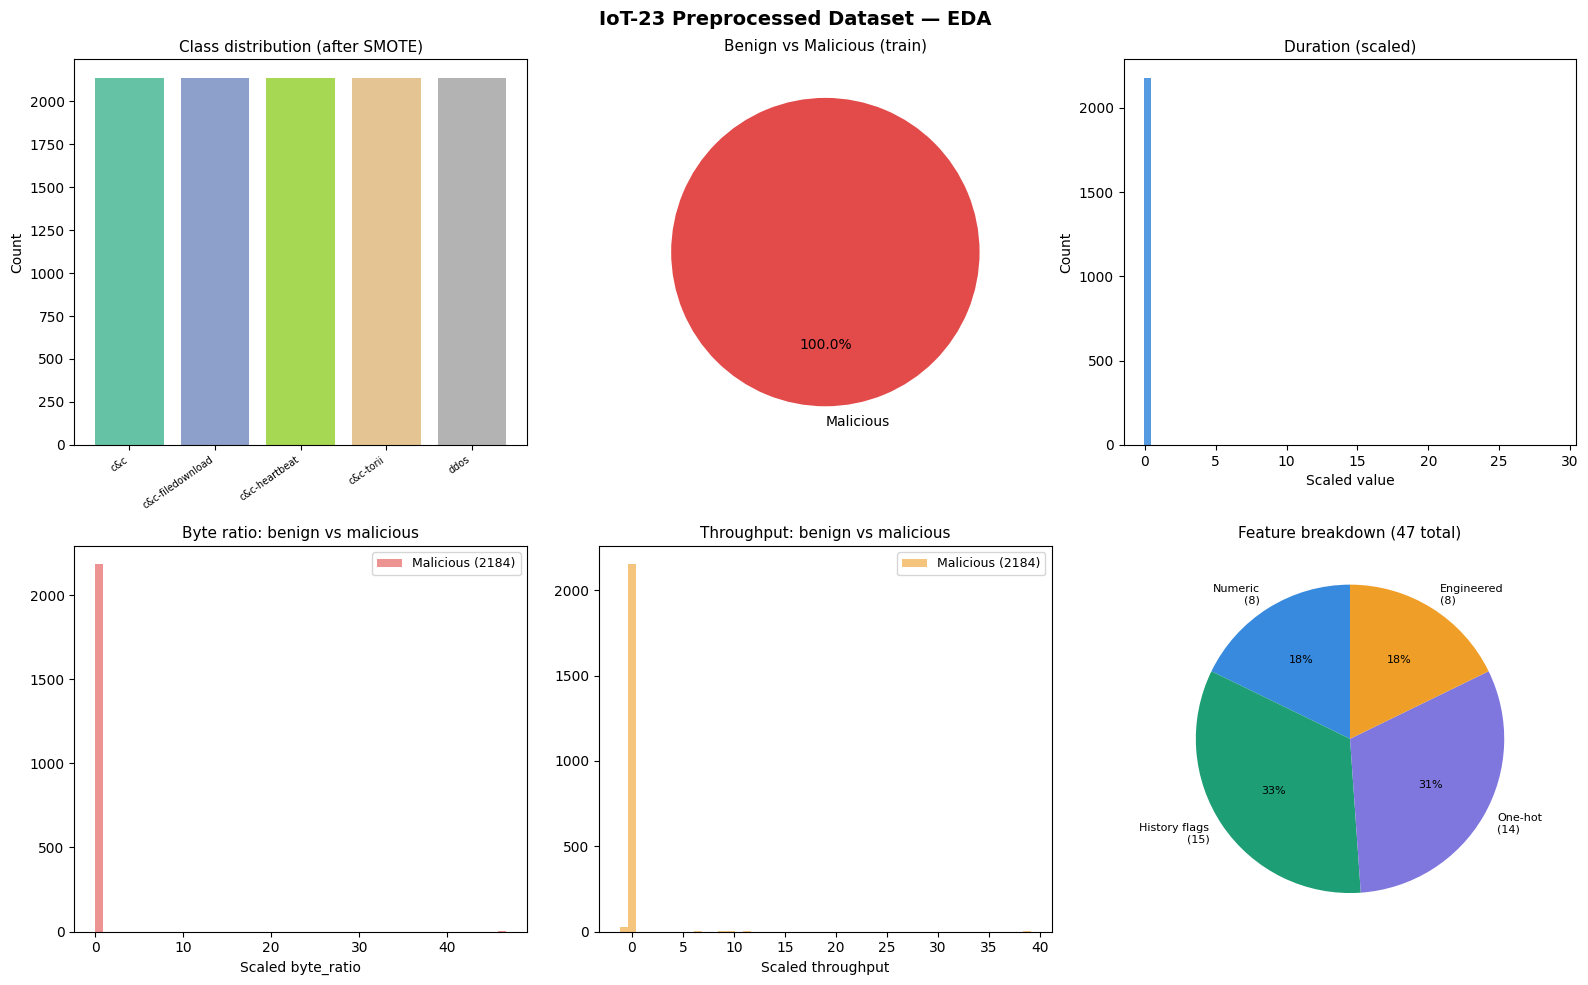

Plot saved to /content/preprocessed/eda_overview.png


In [ ]:
# === Cell 17 — EDA plots ===

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('IoT-23 Preprocessed Dataset — EDA', fontsize=14, fontweight='bold')
inv_label_map = {v: k for k, v in label_map.items()}

# 1. Class distribution after SMOTE
ax = axes[0, 0]
class_counts = pd.Series(y_train_resampled).value_counts().sort_index()
colors_bar   = plt.cm.Set2(np.linspace(0, 1, len(class_counts)))
ax.bar(range(len(class_counts)), class_counts.values, color=colors_bar)
ax.set_xticks(range(len(class_counts)))
ax.set_xticklabels(
    [inv_label_map.get(i, str(i)) for i in class_counts.index],
    rotation=35, ha='right', fontsize=7
)
ax.set_title('Class distribution (after SMOTE)', fontsize=11)
ax.set_ylabel('Count')

# 2. Binary split pie — labels built dynamically from actual data
ax = axes[0, 1]
bin_counts  = pd.Series(y_train_bin).value_counts().sort_index()
bin_labels  = ['Benign' if i == 0 else 'Malicious' for i in bin_counts.index]
bin_colors  = ['#1D9E75' if i == 0 else '#E24B4A'  for i in bin_counts.index]
ax.pie(
    bin_counts.values,
    labels=bin_labels,
    colors=bin_colors,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 10}
)
ax.set_title('Benign vs Malicious (train)', fontsize=11)

# 3. Duration distribution
ax = axes[0, 2]
if 'duration' in FEATURE_COLS:
    idx = FEATURE_COLS.index('duration')
    ax.hist(X_train_scaled[:, idx], bins=60,
            color='#378ADD', alpha=0.85, edgecolor='none')
    ax.set_title('Duration (scaled)', fontsize=11)
    ax.set_xlabel('Scaled value')
    ax.set_ylabel('Count')
else:
    ax.text(0.5, 0.5, 'duration not available',
            ha='center', va='center', fontsize=10)
    ax.set_title('Duration', fontsize=11)

# 4. Byte ratio: benign vs malicious
ax = axes[1, 0]
if 'byte_ratio' in FEATURE_COLS:
    idx = FEATURE_COLS.index('byte_ratio')
    benign_vals  = X_train_scaled[y_train_bin == 0, idx]
    attack_vals  = X_train_scaled[y_train_bin == 1, idx]
    if len(benign_vals) > 0:
        ax.hist(benign_vals, bins=50, alpha=0.6,
                label=f'Benign ({len(benign_vals)})',
                color='#1D9E75', edgecolor='none')
    if len(attack_vals) > 0:
        ax.hist(attack_vals, bins=50, alpha=0.6,
                label=f'Malicious ({len(attack_vals)})',
                color='#E24B4A', edgecolor='none')
    ax.set_title('Byte ratio: benign vs malicious', fontsize=11)
    ax.set_xlabel('Scaled byte_ratio')
    ax.legend(fontsize=9)
else:
    ax.text(0.5, 0.5, 'byte_ratio not available',
            ha='center', va='center', fontsize=10)
    ax.set_title('Byte ratio', fontsize=11)

# 5. Throughput: benign vs malicious
ax = axes[1, 1]
if 'throughput' in FEATURE_COLS:
    idx = FEATURE_COLS.index('throughput')
    benign_tp = X_train_scaled[y_train_bin == 0, idx]
    attack_tp = X_train_scaled[y_train_bin == 1, idx]
    if len(benign_tp) > 0:
        ax.hist(benign_tp, bins=50, alpha=0.6,
                label=f'Benign ({len(benign_tp)})',
                color='#7F77DD', edgecolor='none')
    if len(attack_tp) > 0:
        ax.hist(attack_tp, bins=50, alpha=0.6,
                label=f'Malicious ({len(attack_tp)})',
                color='#EF9F27', edgecolor='none')
    ax.set_title('Throughput: benign vs malicious', fontsize=11)
    ax.set_xlabel('Scaled throughput')
    ax.legend(fontsize=9)
else:
    ax.text(0.5, 0.5, 'throughput not available',
            ha='center', va='center', fontsize=10)
    ax.set_title('Throughput', fontsize=11)

# 6. Feature breakdown pie
ax = axes[1, 2]
n_num    = len([c for c in FEATURE_COLS if c in NUMERIC_COLS])
n_hist   = len([c for c in FEATURE_COLS if c.startswith('hist_')])
n_onehot = len([c for c in FEATURE_COLS
                if any(c.startswith(p)
                       for p in ['proto_', 'service_', 'conn_state_', 'port_'])])
n_eng    = len([c for c in FEATURE_COLS
                if c in ['byte_ratio', 'pkt_ratio', 'ip_byte_ratio',
                         'orig_bytes_per_pkt', 'resp_bytes_per_pkt',
                         'throughput', 'total_bytes', 'total_pkts']])

# Build dynamically — only include categories that have at least 1 feature
sizes      = [n_num, n_hist, n_onehot, n_eng]
categories = ['Numeric', 'History flags', 'One-hot', 'Engineered']
colors_pie = ['#378ADD', '#1D9E75', '#7F77DD', '#EF9F27']

# Filter out zero-count categories to avoid pie chart errors
filtered = [(s, c, col) for s, c, col in zip(sizes, categories, colors_pie) if s > 0]
f_sizes, f_cats, f_colors = zip(*filtered) if filtered else ([1], ['No features'], ['#888'])

ax.pie(
    f_sizes,
    labels=[f'{c}\n({s})' for s, c in zip(f_sizes, f_cats)],
    colors=f_colors,
    autopct='%1.0f%%',
    startangle=90,
    textprops={'fontsize': 8}
)
ax.set_title(f'Feature breakdown ({len(FEATURE_COLS)} total)', fontsize=11)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot saved to {OUTPUT_DIR}eda_overview.png')

## Cell 18 — Save all outputs

In [ ]:
# ── Stage 1: Autoencoder data ─────────────────────────────
np.save(f'{OUTPUT_DIR}X_ae_train.npy', X_ae_train)   # benign only
np.save(f'{OUTPUT_DIR}X_ae_val.npy',   X_ae_val)     # benign only
np.save(f'{OUTPUT_DIR}X_ae_test.npy',  X_ae_test)    # full test
np.save(f'{OUTPUT_DIR}y_ae_test.npy',  y_test_bin)   # binary labels

# ── Stage 2: Classifier data ─────────────────────────────
np.save(f'{OUTPUT_DIR}X_clf_train.npy', X_train_resampled)
np.save(f'{OUTPUT_DIR}y_clf_train.npy', y_train_resampled)
np.save(f'{OUTPUT_DIR}X_clf_test.npy',  X_test_scaled)
np.save(f'{OUTPUT_DIR}y_clf_test.npy',  y_test_multi)

print('=== All files saved ===')
print()
for fname in sorted(os.listdir(OUTPUT_DIR)):
    fpath   = os.path.join(OUTPUT_DIR, fname)
    size_mb = os.path.getsize(fpath) / (1024**2)
    print(f'  {fname:35s} {size_mb:.2f} MB')

print()
print('=== Summary ===')
print(f'  Total features             : {len(FEATURE_COLS)}')
print(f'  AE train rows (benign)     : {X_ae_train.shape[0]}')
print(f'  CLF train rows (resampled) : {X_train_resampled.shape[0]}')
print(f'  Test rows                  : {X_test_scaled.shape[0]}')
print(f'  Attack classes             : {len(label_map)}')

=== All files saved ===

  X_ae_test.npy                       0.10 MB
  X_ae_train.npy                      0.00 MB
  X_ae_val.npy                        0.00 MB
  X_clf_test.npy                      0.10 MB
  X_clf_train.npy                     1.92 MB
  eda_overview.png                    0.16 MB
  feature_names.json                  0.00 MB
  label_map.json                      0.00 MB
  scaler.pkl                          0.00 MB
  y_ae_test.npy                       0.00 MB
  y_clf_test.npy                      0.00 MB
  y_clf_train.npy                     0.08 MB

=== Summary ===
  Total features             : 47
  AE train rows (benign)     : 0
  CLF train rows (resampled) : 10690
  Test rows                  : 546
  Attack classes             : 5


## Cell 19 — Copy everything to Google Drive

In [ ]:
DRIVE_OUTPUT = '/content/drive/MyDrive/IoT23 CSVs-ML/preprocessed/'
os.makedirs(DRIVE_OUTPUT, exist_ok=True)

for fname in os.listdir(OUTPUT_DIR):
    src = os.path.join(OUTPUT_DIR, fname)
    dst = os.path.join(DRIVE_OUTPUT, fname)
    shutil.copy(src, dst)
    print(f'  Copied: {fname}')

print(f'\nAll files saved to Google Drive: {DRIVE_OUTPUT}')

  Copied: y_clf_train.npy
  Copied: y_clf_test.npy
  Copied: feature_names.json
  Copied: label_map.json
  Copied: y_ae_test.npy
  Copied: eda_overview.png
  Copied: X_clf_train.npy
  Copied: X_clf_test.npy
  Copied: scaler.pkl
  Copied: X_ae_test.npy
  Copied: X_ae_train.npy
  Copied: X_ae_val.npy

All files saved to Google Drive: /content/drive/MyDrive/IoT23 CSVs-ML/preprocessed/


## Output file reference

| File | Stage | Purpose |
|---|---|---|
| `X_ae_train.npy` | Stage 1 — Autoencoder | Training on benign traffic only |
| `X_ae_val.npy` | Stage 1 — Autoencoder | Calibrate reconstruction threshold |
| `X_ae_test.npy` + `y_ae_test.npy` | Stage 1 — Autoencoder | Evaluate anomaly detection |
| `X_clf_train.npy` + `y_clf_train.npy` | Stage 2 — Classifier | Train DT / SVM / 1D-CNN |
| `X_clf_test.npy` + `y_clf_test.npy` | Stage 2 — Classifier | Evaluate attack classification |
| `scaler.pkl` | Inference | Scale live traffic at deployment |
| `label_map.json` | Inference | Decode predicted integers to attack names |
| `feature_names.json` | All stages | Track which feature is at which index |

In [ ]:
import os
import numpy as np

DRIVE_OUTPUT = '/content/drive/MyDrive/IoT23 CSVs-ML/preprocessed/'

files = os.listdir(DRIVE_OUTPUT)
print('Files in Drive:')
for f in sorted(files):
    size = os.path.getsize(os.path.join(DRIVE_OUTPUT, f)) / (1024**2)
    print(f'  {f:35s} {size:.2f} MB')

# Quick shape check
X_ae_train = np.load(f'{DRIVE_OUTPUT}X_ae_train.npy')
X_clf_train = np.load(f'{DRIVE_OUTPUT}X_clf_train.npy')
print(f'\nX_ae_train shape  : {X_ae_train.shape}')
print(f'X_clf_train shape : {X_clf_train.shape}')

Files in Drive:
  X_ae_test.npy                       0.10 MB
  X_ae_train.npy                      0.00 MB
  X_ae_val.npy                        0.00 MB
  X_clf_test.npy                      0.10 MB
  X_clf_train.npy                     1.92 MB
  eda_overview.png                    0.16 MB
  feature_names.json                  0.00 MB
  label_map.json                      0.00 MB
  scaler.pkl                          0.00 MB
  y_ae_test.npy                       0.00 MB
  y_clf_test.npy                      0.00 MB
  y_clf_train.npy                     0.08 MB

X_ae_train shape  : (0, 47)
X_clf_train shape : (10690, 47)
